# Nhóm 11 – Phân loại trái cây bằng CNN

Notebook dùng mã nguồn của dự án để kiểm tra dữ liệu, huấn luyện MobileNetV2 và tái tạo các hình thống kê trong báo cáo.

Mở notebook ở thư mục gốc dự án và chọn kernel Python của `.venv`. Nếu cần đăng ký kernel, chạy từ PowerShell ở thư mục dự án:

```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements.txt ipykernel
.\.venv\Scripts\python.exe -m ipykernel install --user --name duanhocmay --display-name "Python (DuanHocMay)"
```

Chọn **Python (DuanHocMay)** và bấm **Run All** để tạo lại các hình, kiểm thử mô hình đã lưu và xem ví dụ dự đoán. Giữ `src/`, `dataset/`, `models/` và `results/labels.csv` cùng dự án để chạy lại. Bật công tắc ở mục 3 nếu cần huấn luyện lại.

In [1]:
import json
import os
from pathlib import Path
import subprocess
import sys
from tempfile import TemporaryDirectory

import pandas as pd
from IPython.display import Code, Image, display

root = Path.cwd().resolve()
if not (root / "src" / "train_fruit_transfer.py").is_file():
    raise RuntimeError("Hãy mở notebook từ thư mục gốc dự án DuanHocMay.")

manifest = root / "results" / "labels.csv"
models = root / "models"
workspace = TemporaryDirectory(prefix="duanhocmay-notebook-")
artifacts = Path(workspace.name)
env = {
    **os.environ,
    "PYTHONIOENCODING": "utf-8",
    "TF_CPP_MIN_LOG_LEVEL": "2",
    "FRUIT_MODEL_DIR": str(models),
}

def run_python(*arguments):
    result = subprocess.run(
        [sys.executable, "-X", "utf8", *map(str, arguments)],
        cwd=root, env=env, capture_output=True, encoding="utf-8", errors="replace",
    )
    if result.returncode:
        raise RuntimeError(f"Lệnh Python thất bại:\n{result.stdout}{result.stderr}")
    return result.stdout

print("Phiên bản Python:", sys.version.split()[0])

Phiên bản Python: 3.11.9


## 1. Dữ liệu và ảnh mẫu

`src.inspect_dataset` đọc manifest và lấy một ảnh huấn luyện cho mỗi nhãn để ghép **Hình 2.1**. Notebook tạo lại bảng và hình khi chạy ô bên dưới.

2610 ảnh nguồn, 2557 ảnh trong manifest, 11 nhãn.


,train,val,test,total
label,,,,
Bưởi,91,20,20,131
Cam,175,37,38,250
Chuối,175,37,38,250
Dưa hấu,175,37,38,250
Lê,175,37,38,250
Mít,168,5,7,180
Nho,175,37,38,250
Quýt,172,37,37,246
Thơm,175,37,38,250


Tổng từng tập: {'train': 1831, 'val': 358, 'test': 368, 'total': 2557}


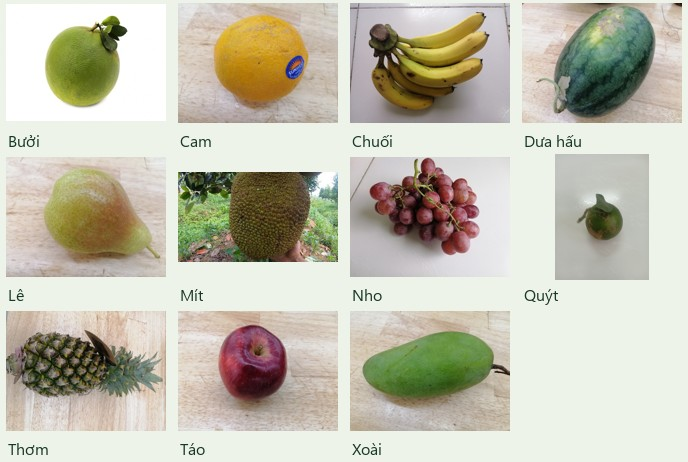

In [2]:
audit_dir = artifacts / "dataset"
print(run_python("-m", "src.inspect_dataset", "--manifest", manifest, "--output-dir", audit_dir).strip())
distribution = pd.read_csv(audit_dir / "class_summary.csv").set_index("label")
display(distribution)
print("Tổng từng tập:", distribution.sum().to_dict())
display(Image(filename=str(audit_dir / "dataset_samples.jpg"), width=680))

## 2. Mã nguồn huấn luyện

Bộ phân loại đóng băng phần trích đặc trưng MobileNetV2, tăng cường ảnh huấn luyện và thử ba giá trị điều chuẩn cho hồi quy logistic. Chương trình chọn mô hình theo kết quả validation, lưu checkpoint Keras và kiểm thử trên tập test giữ lại.

Ô bên dưới đọc và hiển thị toàn bộ mã nguồn huấn luyện bộ phân loại. Mã huấn luyện bộ lọc ảnh có trái cây nằm ở [src/train_fruit_presence.py](src/train_fruit_presence.py). Khi huấn luyện lại ở mục 3, bộ phân loại lấy phần trích đặc trưng từ checkpoint bộ lọc hiện có.

In [3]:
display(Code(filename=str(root / "src" / "train_fruit_transfer.py"), language="python"))

"""Fit a fruit classifier on the frozen MobileNetV2 image features."""
import argparse
import json
from pathlib import Path
from time import monotonic

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import tensorflow as tf
from tensorflow import keras

from config import MODELS, RESULTS
from src.evaluate import evaluate
from src.predict import load_presence_classifier
from src.preprocess import make_dataset, read_labels


def encode(dataset, encoder, augment=None):
    features, labels = [], []
    for images, batch_labels in dataset:
        features.append(encoder(images, training=False).numpy())
        labels.append(batch_labels.numpy())
        if augment is not None:
            for _ in range(2):
                features.append(encoder(augment(images, training=True), training=False).numpy())
                labels.append(batch_labels.numpy())
    return np.concatenate(features), np.concatenate(labels)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--output-dir", type=Path, default=RESULTS / "mobilenet_transfer")
    parser.add_argument("--manifest", type=Path, default=RESULTS / "labels.csv")
    args = parser.parse_args()
    output = args.output_dir
    output.mkdir(parents=True, exist_ok=True)

    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
    keras.utils.set_random_seed(42)
    start = monotonic()
    splits, classes = read_labels(args.manifest)
    presence = load_presence_classifier(MODELS)
    encoder = keras.Model(presence.inputs, presence.get_layer("fruit_score").input)
    encoder.trainable = False

    augment = keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(.08, fill_mode="constant", fill_value=230),
        keras.layers.RandomZoom((-.12, .22), fill_mode="constant", fill_value=230),
        keras.layers.RandomTranslation(.09, .09, fill_mode="constant", fill_value=230),
        keras.layers.RandomBrightness(.12, value_range=(0, 255)),
    ])
    batch_size = 24
    train = make_dataset(splits["train"], classes, batch_size)
    validation = make_dataset(splits["val"], classes, batch_size)
    train_features, train_labels = encode(train, encoder, augment)
    val_features, val_labels = encode(validation, encoder)

    candidates = []
    for regularization in (.03, .15, .75):
        candidate = LogisticRegression(C=regularization, class_weight="balanced", max_iter=500)
        candidate.fit(train_features, train_labels)
        scores = candidate.predict_proba(val_features)
        accuracy = float(np.mean(scores.argmax(axis=1) == val_labels))
        loss = log_loss(val_labels, scores, labels=candidate.classes_)
        candidates.append((accuracy, loss, candidate))
        print(f"C={regularization}: val_accuracy={accuracy:.4f}, val_loss={loss:.4f}", flush=True)
    accuracy, loss, classifier = max(candidates, key=lambda item: (item[0], -item[1]))

    head = keras.layers.Dense(len(classes), activation="softmax", name="fruit_name")
    model = keras.Model(encoder.inputs, head(encoder.output), name="fruit_mobilenet")
    head.set_weights([classifier.coef_.T, classifier.intercept_])
    checkpoint = output / "fruit_classifier.keras"
    model.save(checkpoint)
    (output / "class_names.json").write_text(json.dumps(classes, ensure_ascii=False, indent=2), encoding="utf-8")
    (output / "validation.json").write_text(json.dumps({
        "accuracy": accuracy, "loss": loss, "C": classifier.C, "images": len(val_labels),
    }, indent=2), encoding="utf-8")
    evaluate(checkpoint, output, splits, classes, batch_size, monotonic() - start)


if __name__ == "__main__":
    main()

## 3. Huấn luyện lại bộ phân loại

Đặt `TRAIN_AGAIN = True` và chạy ô này để tạo checkpoint mới trong `results/notebook_training/`. Mục 4 dùng checkpoint trong `models/` để đối chiếu với báo cáo. Kết quả huấn luyện mới có thể khác tùy môi trường.

In [4]:
TRAIN_AGAIN = False

if TRAIN_AGAIN:
    training_output = root / "results" / "notebook_training"
    print(run_python(
        "-m", "src.train_fruit_transfer", "--manifest", manifest, "--output-dir", training_output,
    ).strip())
    print("Checkpoint mới:", training_output.relative_to(root) / "fruit_classifier.keras")
else:
    print("Đang dùng checkpoint đã lưu. Đặt TRAIN_AGAIN = True để huấn luyện lại.")

Đang dùng checkpoint đã lưu. Đặt TRAIN_AGAIN = True để huấn luyện lại.


## 4. Kiểm thử và tạo biểu đồ

Hàm `evaluate` đọc checkpoint trong `models/` và dự đoán từng ảnh test. Kết quả gồm biểu đồ số ảnh theo từng nhãn (**Hình 2.2**), ma trận nhầm lẫn (**Hình 4.3**) và bảng kết quả theo lớp. Hàng trong ma trận là nhãn thật, cột là nhãn dự đoán.

Các hình được hiển thị ngay bên dưới. Tệp trung gian được ghi vào thư mục tạm của phiên chạy.

Đúng top 1: 342/368 ảnh (92.93%)


,precision,recall,f1-score,support
Bưởi,1.0000,1.0000,1.0000,20.0000
Cam,1.0000,1.0000,1.0000,38.0000
Chuối,1.0000,1.0000,1.0000,38.0000
Dưa hấu,0.9048,1.0000,0.9500,38.0000
Lê,0.7674,0.8684,0.8148,38.0000
Mít,1.0000,1.0000,1.0000,7.0000
Nho,1.0000,1.0000,1.0000,38.0000
Quýt,1.0000,1.0000,1.0000,37.0000
Thơm,1.0000,1.0000,1.0000,38.0000
Táo,0.8000,0.6316,0.7059,38.0000


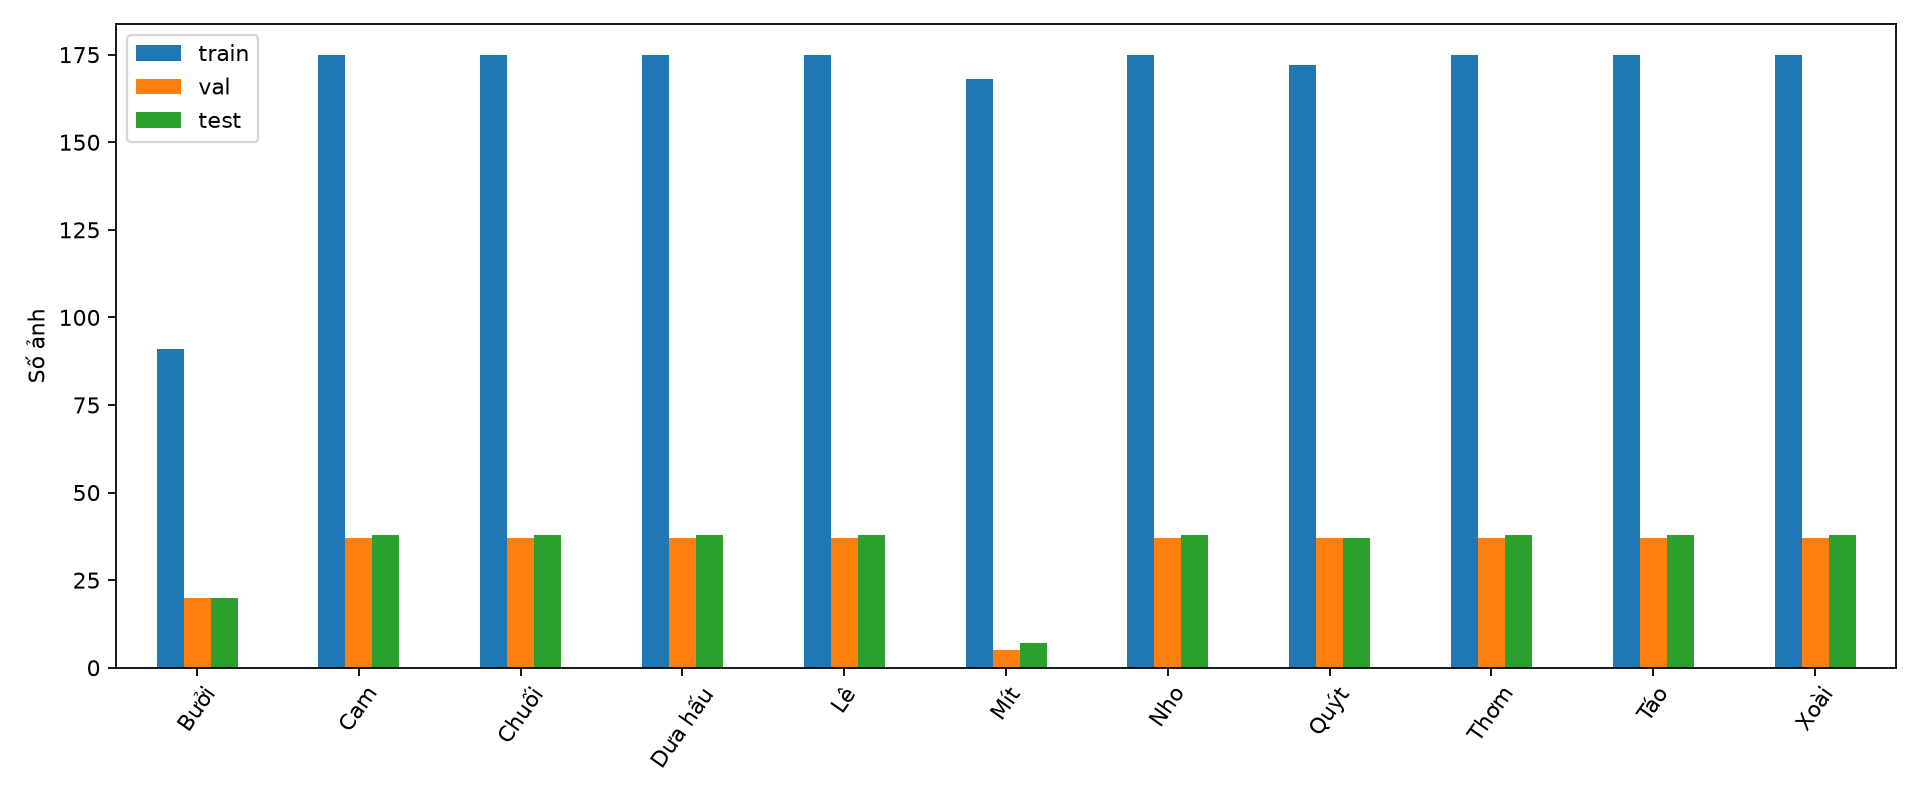

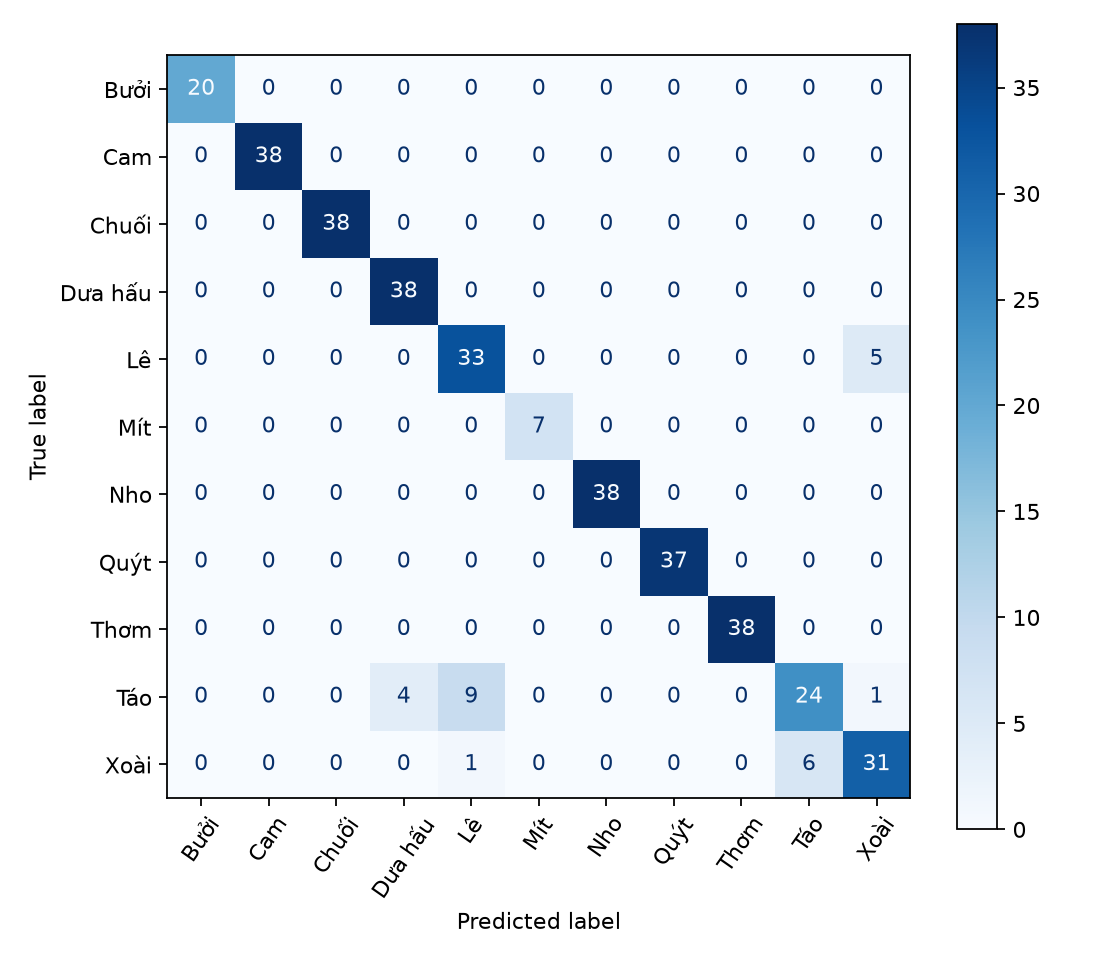

In [5]:
evaluation_dir = artifacts / "evaluation"
evaluation_dir.mkdir(exist_ok=True)
evaluation_code = """
import json
from pathlib import Path
import sys

from src.evaluate import evaluate
from src.preprocess import read_labels

manifest, models, output = map(Path, sys.argv[1:])
splits, classes = read_labels(manifest)
saved_classes = json.loads((models / "class_names.json").read_text(encoding="utf-8"))
if classes != saved_classes:
    raise ValueError("Thứ tự nhãn trong manifest khác checkpoint.")
evaluate(models / "fruit_classifier.keras", output, splits, classes)
"""
run_python("-c", evaluation_code, manifest, models, evaluation_dir)

predictions = pd.read_csv(evaluation_dir / "test_predictions.csv")
correct = predictions["actual"].eq(predictions["predicted"]).sum()
print(f"Đúng top 1: {correct}/{len(predictions)} ảnh ({correct / len(predictions):.2%})")
display(pd.read_csv(evaluation_dir / "classification_report.csv", index_col=0).round(4))
display(Image(filename=str(evaluation_dir / "class_counts.png"), width=850))
display(Image(filename=str(evaluation_dir / "confusion_matrix.png"), width=690))

## 5. Dự đoán ảnh Cam

`cam_249.jpg` là ảnh test dùng để chụp màn hình website ở Hình 4.1 và 4.2. Notebook gọi cùng hàm dự đoán với website để chạy bộ lọc và hiển thị ba nhãn có điểm cao nhất.

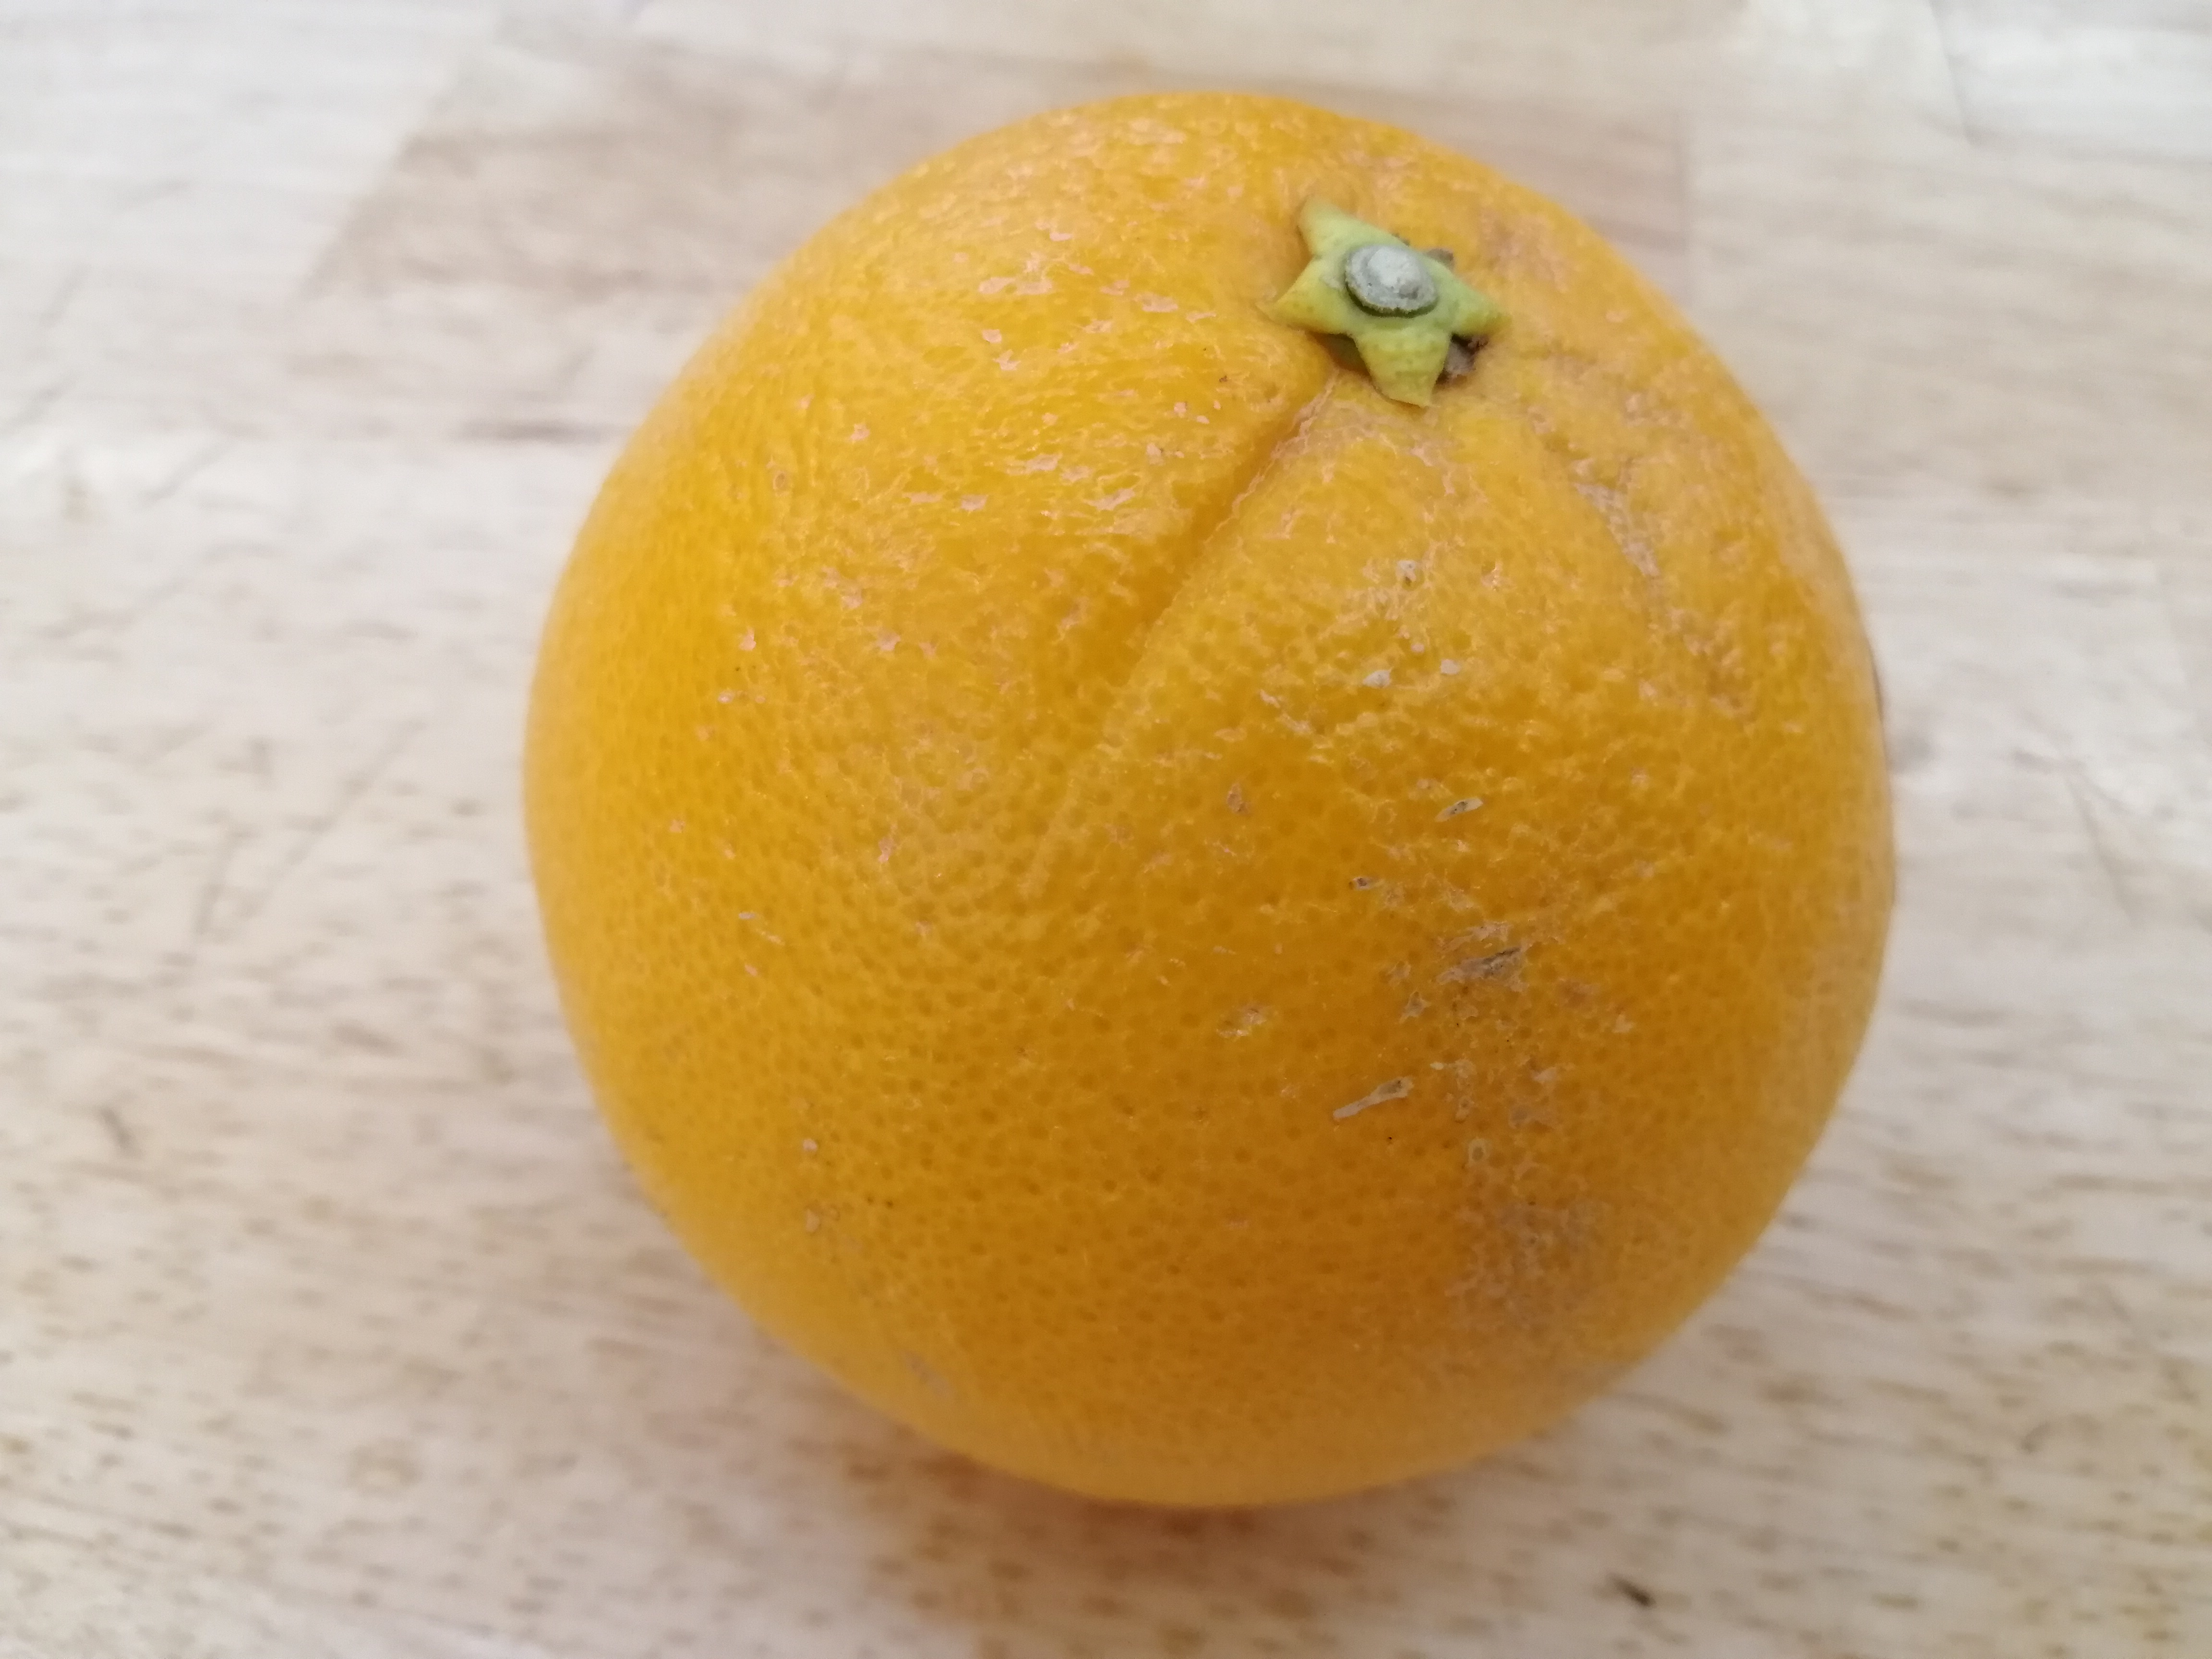

1. Cam: 99.79%
2. Bưởi: 0.13%
3. Lê: 0.05%


In [6]:
example = root / "dataset" / "anhtraicay" / "data" / "cam" / "cam_249.jpg"
display(Image(filename=str(example), width=280))
example_result = json.loads(run_python("-m", "src.predict", example))
if example_result["non_fruit"]:
    print("Không phát hiện trái cây.")
else:
    for rank, item in enumerate(example_result["top3"], start=1):
        print(f"{rank}. {item['label']}: {item['probability']:.2%}")